# EDA — ERA5-Land en Algérie

Ce notebook explore les dimensions, variables et unités, mesure les valeurs manquantes, examine les séries temporelles et projette les cellules ERA5 sur les frontières des 58 wilayas du fichier `data/geo/dz.json`.

La période réelle dépend des fichiers téléchargés. La grille a été agrégée spatialement par blocs de 4 × 4 cellules source (environ 0,4°); les frontières servent au masque, et les statistiques par wilaya sont donc des estimations à cette résolution. Les champs statiques (sols, couverture, etc.) ne varient pas dans le temps.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon
from shapely.geometry import shape
from shapely import contains_xy

# Trouver la racine du projet même si Jupyter a démarré dans notebooks/.
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / 'data' / 'processed').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Racine du projet introuvable; lancez Jupyter depuis le projet.')
processed_dir = ROOT / 'data' / 'processed'
nc_files = sorted(processed_dir.glob('era5_land_algeria_monthly_*_all.nc'))
if not nc_files:
    raise FileNotFoundError(f'Aucun NetCDF fusionné dans {processed_dir}; lancez src/merge_era5.py.')
DATA_PATH = nc_files[-1]
GEO_PATH = ROOT / 'data' / 'geo' / 'dz.json'
ds = xr.open_dataset(DATA_PATH)
print('Fichier :', DATA_PATH.name)
print('Dimensions :', dict(ds.sizes))
print('Période :', str(ds.time.values[0])[:10], '→', str(ds.time.values[-1])[:10])
print("Nombre d’attributs :", len(ds.attrs))
print('Attributs :', ds.attrs)
print("Nombre de variables :", len(ds.data_vars))
print(list(ds.data_vars))
    

Fichier : era5_land_algeria_monthly_2015-01_2026-07_all.nc
Dimensions : {'time': 139, 'latitude': 46, 'longitude': 52}
Période : 2015-01-01 → 2026-07-01
Nombre d’attributs : 12
Attributs : {'GRIB_centre': 'ecmf', 'GRIB_centreDescription': 'European Centre for Medium-Range Weather Forecasts', 'GRIB_subCentre': np.int64(0), 'Conventions': 'CF-1.7', 'institution': 'European Centre for Medium-Range Weather Forecasts', 'history': '2026-10-22T23:12 GRIB to CDM+CF via cfgrib-0.9.15.1/ecCodes-2.48.2 with {"source": "data.grib", "filter_by_keys": {"stream": ["moda"]}, "encode_cf": ["parameter", "time", "geography", "vertical"]}', 'source': 'Copernicus Climate Data Store, ERA5-Land monthly averaged reanalysis', 'source_dataset': 'reanalysis-era5-land-monthly-means', 'study_area': 'Algeria; polygon mask from data/geo/dz.json (SimpleMaps)', 'spatial_aggregation': 'mean of 4x4 source grid cells; categorical classes use mode', 'source_grid_resolution': '0.1 degree', 'time_period': '2015-01 to 2026-0

## 1. Inventaire des variables et unités

Les noms courts (par exemple `t2m`, `tp`) sont les identifiants conservés dans le NetCDF. Les champs demandés au CDS ne correspondent pas toujours un à un à ces noms: le tableau montre le nom, la description et l’unité réellement stockés. Une unité telle que `J m**-2` correspond à une énergie intégrée sur la période mensuelle, pas à une puissance moyenne.

In [2]:
inventory = pd.DataFrame([
    {'variable': name, 'description': da.attrs.get('long_name', ''),
     'unité': da.attrs.get('units', 'non renseignée'),
     'dimensions': ' × '.join(f'{k}={v}' for k, v in da.sizes.items()),
     'temporelle': 'oui' if 'time' in da.dims else 'non (statique)'}
    for name, da in ds.data_vars.items()
])
display(inventory)
print(f'{len(inventory)} variables: {(inventory.temporelle == "oui").sum()} temporelles et {(inventory.temporelle == "non (statique)").sum()} statiques.')


,variable,description,unité,dimensions,temporelle
0,t2m,2 metre temperature,K,time=139 × latitude=46 × longitude=52,oui
1,d2m,2 metre dewpoint temperature,K,time=139 × latitude=46 × longitude=52,oui
2,slhf,Time-integrated surface latent heat net flux,J m**-2,time=139 × latitude=46 × longitude=52,oui
3,ssr,Surface net short-wave (solar) radiation,J m**-2,time=139 × latitude=46 × longitude=52,oui
4,str,Surface net long-wave (thermal) radiation,J m**-2,time=139 × latitude=46 × longitude=52,oui
5,sshf,Time-integrated surface sensible heat net flux,J m**-2,time=139 × latitude=46 × longitude=52,oui
6,ro,Runoff,m,time=139 × latitude=46 × longitude=52,oui
7,e,Evaporation,m of water equivalent,time=139 × latitude=46 × longitude=52,oui
8,u10,10 metre U wind component,m s**-1,time=139 × latitude=46 × longitude=52,oui
9,v10,10 metre V wind component,m s**-1,time=139 × latitude=46 × longitude=52,oui


54 variables: 44 temporelles et 10 statiques.


### Vérification des champs demandés au CDS

Le NetCDF ne contient pas forcément une variable par intitulé du formulaire: certains champs ont été codés sous un nom court ou regroupés par le CDS/GRIB. Dans les archives de ce projet, les noms ci-dessous n’ont pas de variable correspondante visible dans le NetCDF fusionné; il faut vérifier les archives brutes si ces champs sont nécessaires.

In [3]:
cds_fields_not_found = [
    'snow_cover',
    'evaporation_from_bare_soil',
    'evaporation_from_open_water_surfaces_excluding_oceans',
    'evaporation_from_the_top_of_canopy',
    'evaporation_from_vegetation_transpiration',
]
display(pd.DataFrame({'champ CDS demandé mais absent du NetCDF fusionné': cds_fields_not_found}))
print('Le champ `sd` présent dans le fichier est décrit comme :', ds['sd'].attrs if 'sd' in ds else 'absent')


,champ CDS demandé mais absent du NetCDF fusionné
0,snow_cover
1,evaporation_from_bare_soil
2,evaporation_from_open_water_surfaces_excluding...
3,evaporation_from_the_top_of_canopy
4,evaporation_from_vegetation_transpiration


Le champ `sd` présent dans le fichier est décrit comme : {'GRIB_paramId': np.int64(141), 'GRIB_dataType': 'an', 'GRIB_numberOfPoints': np.int64(38064), 'GRIB_typeOfLevel': 'surface', 'GRIB_stepUnits': np.int64(1), 'GRIB_gridType': 'regular_ll', 'GRIB_uvRelativeToGrid': np.int64(0), 'GRIB_NV': np.int64(0), 'GRIB_Nx': np.int64(208), 'GRIB_Ny': np.int64(183), 'GRIB_cfName': 'lwe_thickness_of_surface_snow_amount', 'GRIB_cfVarName': 'sd', 'GRIB_gridDefinitionDescription': 'Latitude/Longitude Grid', 'GRIB_iDirectionIncrementInDegrees': np.float64(0.1), 'GRIB_iScansNegatively': np.int64(0), 'GRIB_jDirectionIncrementInDegrees': np.float64(0.1), 'GRIB_jPointsAreConsecutive': np.int64(0), 'GRIB_jScansPositively': np.int64(0), 'GRIB_latitudeOfFirstGridPointInDegrees': np.float64(37.1), 'GRIB_latitudeOfLastGridPointInDegrees': np.float64(18.9), 'GRIB_longitudeOfFirstGridPointInDegrees': np.float64(-8.7), 'GRIB_longitudeOfLastGridPointInDegrees': np.float64(12.0), 'GRIB_missingValue': np.float64(3.

## 2. Valeurs manquantes

Le masque géographique crée volontairement des `NaN` hors d’Algérie; leur proportion globale ne doit donc pas être interprétée comme une panne de mesure. Le tableau et la carte ci-dessous séparent l’inspection temporelle des champs statiques. Pour les variables climatiques, on suit aussi les mois manquants dans le temps.

,variable,NaN (%),cellules non manquantes
0,t2m,41.05,195990
1,d2m,41.05,195990
2,slhf,41.05,195990
3,ssr,41.05,195990
4,str,41.05,195990
5,sshf,41.05,195990
6,ro,41.05,195990
7,e,41.05,195990
8,u10,41.05,195990
9,v10,41.05,195990


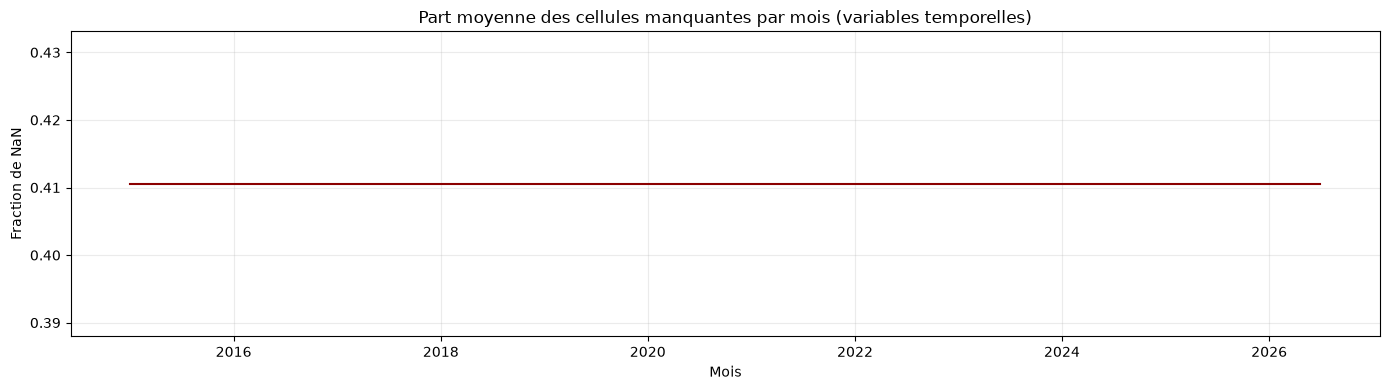

In [4]:
missing = pd.DataFrame([
    {'variable': n, 'NaN (%)': float(ds[n].isnull().mean().values * 100),
     'cellules non manquantes': int(ds[n].count().values)}
    for n in ds.data_vars
])
display(missing.sort_values('NaN (%)', ascending=False).round({'NaN (%)': 2}))

temporal_vars = [n for n in ds.data_vars if 'time' in ds[n].dims]
monthly_missing = xr.Dataset({n: ds[n].isnull().mean(('latitude','longitude')) for n in temporal_vars})
fig, ax = plt.subplots(figsize=(14, 4))
monthly_missing.to_array('variable').mean('variable').plot(ax=ax, color='darkred')
ax.set(title='Part moyenne des cellules manquantes par mois (variables temporelles)', ylabel='Fraction de NaN', xlabel='Mois')
ax.grid(alpha=.25); plt.tight_layout(); plt.show()


## 3. Statistiques et évolution temporelle

On commence par quelques variables météorologiques facilement interprétables. Les températures sont affichées en °C après conversion depuis K; la précipitation `tp` reste dans son unité native (m d’eau). La conversion est appliquée à l’affichage seulement, le NetCDF n’est pas modifié.

,count,mean,std,min,25%,50%,75%,max
t2m,139.0,296.886536,7.928889,282.709961,289.827484,297.441162,304.533997,308.696930
d2m,139.0,274.704376,3.639081,267.926422,271.660126,274.830444,277.279144,285.488739
tp,139.0,0.000183,0.000146,0.000011,0.000070,0.000132,0.000276,0.000776
u10,139.0,-1.000681,0.818111,-2.724575,-1.570879,-1.068330,-0.472135,1.467010
v10,139.0,-0.511531,0.433162,-1.600044,-0.784011,-0.470158,-0.214687,0.392348
sp,139.0,95197.539062,323.060577,94709.648438,94947.898438,95091.609375,95433.164062,96248.875000


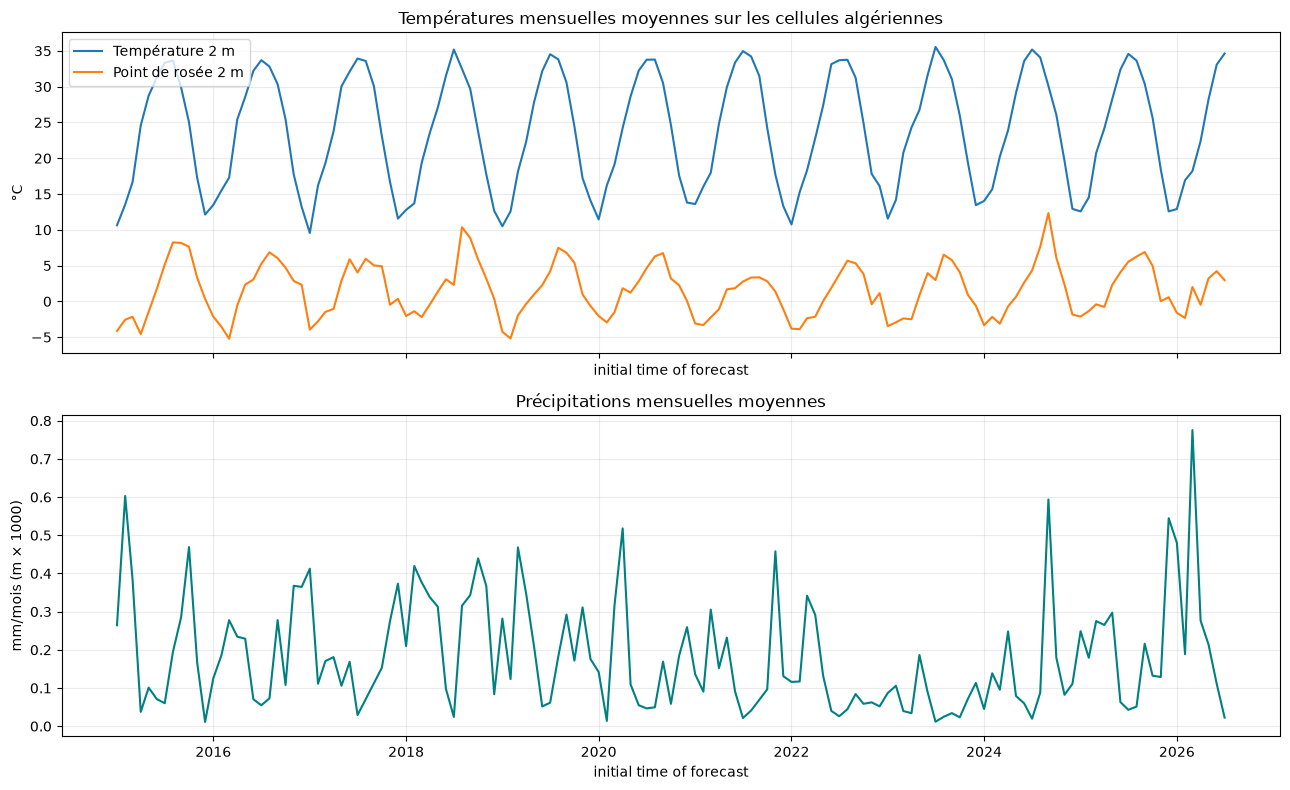

In [5]:
# Statistiques de la moyenne spatiale pour chaque mois (139 valeurs au plus par variable).
key_vars = [n for n in ['t2m','d2m','tp','u10','v10','sp'] if n in ds]
monthly_spatial_means = ds[key_vars].mean(('latitude','longitude')).to_dataframe()
display(monthly_spatial_means.describe().T)

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
if 't2m' in ds:
    (ds.t2m.mean(('latitude','longitude')) - 273.15).plot(ax=axes[0], label='Température 2 m')
if 'd2m' in ds:
    (ds.d2m.mean(('latitude','longitude')) - 273.15).plot(ax=axes[0], label='Point de rosée 2 m')
axes[0].set_ylabel('°C'); axes[0].set_title('Températures mensuelles moyennes sur les cellules algériennes'); axes[0].legend(); axes[0].grid(alpha=.25)
if 'tp' in ds:
    (ds.tp.mean(('latitude','longitude')) * 1000).plot(ax=axes[1], color='teal')
axes[1].set_ylabel('mm/mois (m × 1000)'); axes[1].set_title('Précipitations mensuelles moyennes')
axes[1].grid(alpha=.25); plt.tight_layout(); plt.show()


## 4. Carte des cellules ERA5 et frontières des wilayas

La carte ci-dessous représente les centres des cellules de la grille traitée, colorés par leur température moyenne sur toute la période. Les polygones proviennent de `dz.json`. Les cellules sans valeur après masque ne sont pas dessinées. La résolution réduite explique que les petits territoires soient représentés par peu de points.

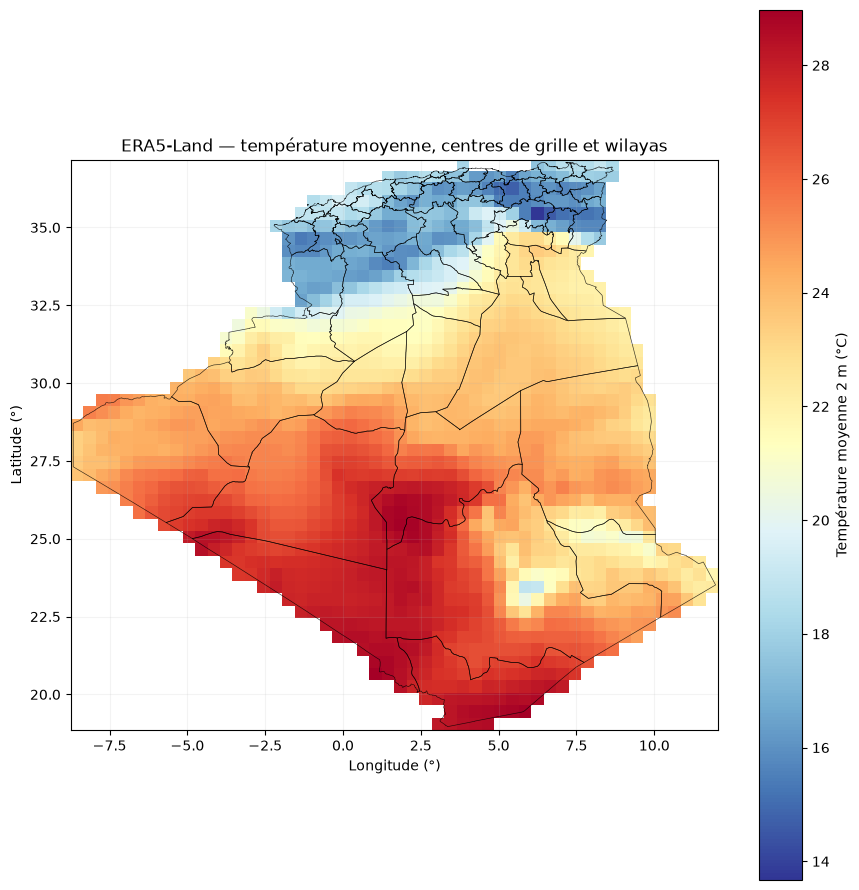

In [6]:
geo = json.loads(GEO_PATH.read_text(encoding='utf-8'))
features = geo['features']
wilayas = [(f.get('properties', {}).get('name', f'Wilaya {i+1}'), shape(f['geometry'])) for i, f in enumerate(features)]

def draw_boundaries(ax):
    # Dessine les anneaux des polygones GeoJSON (y compris les géométries multiparties).
    for _, geom in wilayas:
        parts = list(geom.geoms) if hasattr(geom, 'geoms') else [geom]
        for poly in parts:
            x, y = poly.exterior.xy
            ax.plot(x, y, color='black', linewidth=.45, alpha=.8)

if 't2m' not in ds:
    raise KeyError('La variable t2m est absente; choisissez une variable disponible dans inventory.')
field = ds.t2m.mean('time') - 273.15
fig, ax = plt.subplots(figsize=(9, 9))
m = ax.pcolormesh(ds.longitude, ds.latitude, field, shading='nearest', cmap='RdYlBu_r')
draw_boundaries(ax)
fig.colorbar(m, ax=ax, label='Température moyenne 2 m (°C)')
ax.set(xlabel='Longitude (°)', ylabel='Latitude (°)', title='ERA5-Land — température moyenne, centres de grille et wilayas')
ax.set_aspect('equal', adjustable='box'); ax.grid(alpha=.15); plt.tight_layout(); plt.show()


## 5. Comparaison spatiale entre wilayas

Pour chaque wilaya, on sélectionne les centres de grille situés à l’intérieur du polygone puis on calcule la moyenne de `t2m` sur les mois et cellules retenus. Le nombre de points est affiché pour signaler les estimations fragiles. Avec une grille d’environ 0,4°, plusieurs wilayas peuvent ne contenir aucun centre; leur résultat reste `NaN`, ce qui n’est pas une erreur de données.

,wilaya,points_grille,t2m_moyenne_C
36,Setif,4,15.279785
10,Bordj Bou Arrer,3,15.924225
28,Mila,1,16.002594
14,Constantine,1,16.043365
33,Oum El Bouaghi,4,16.045135
7,Bejaia,2,16.255585
39,Souk-Ahras,2,16.265533
11,Bouira,2,16.304993
22,Jijel,3,16.341888
37,Sidi Bel Abbes,5,16.385742


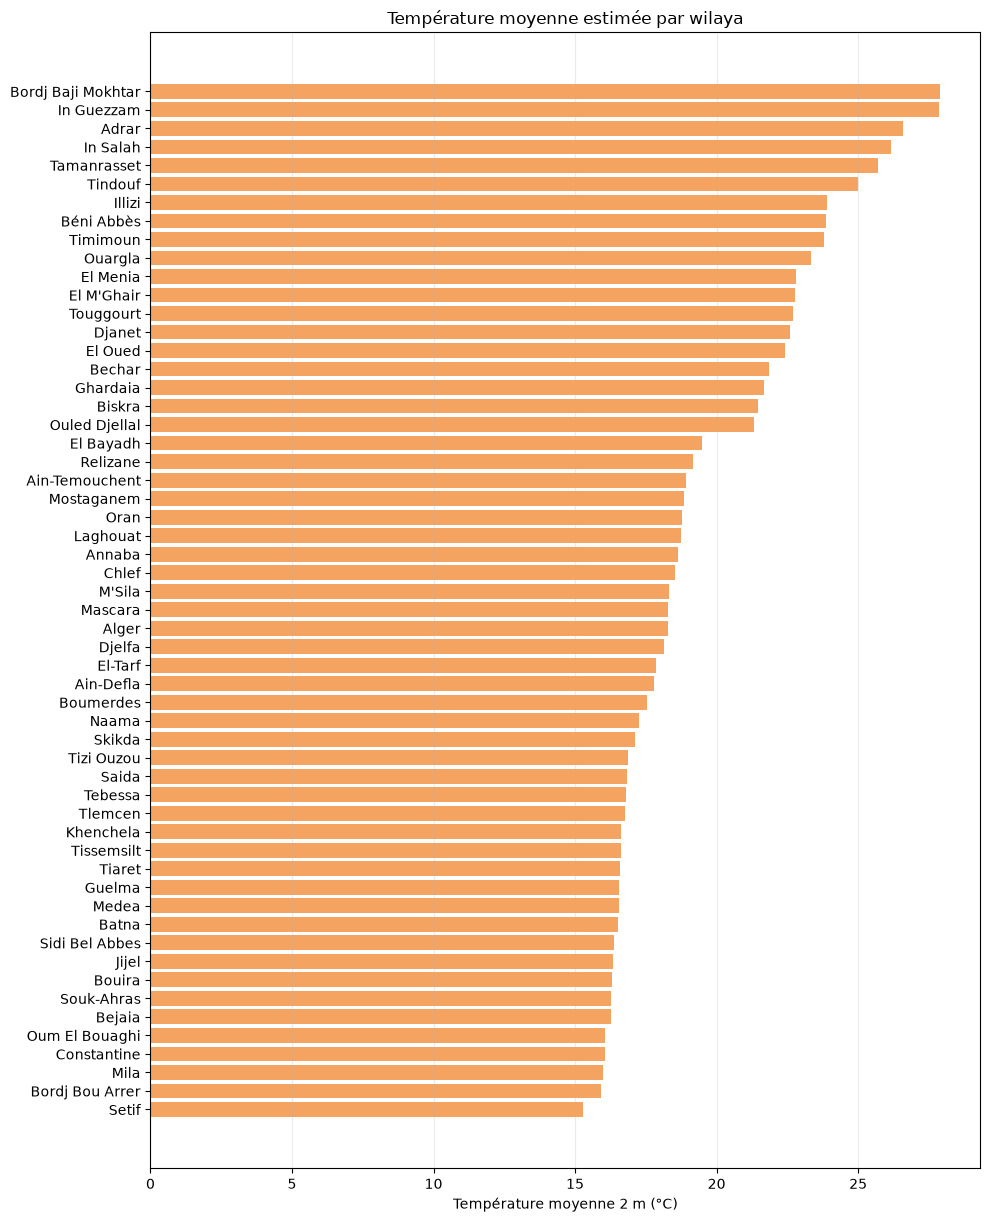

Wilayas avec au moins un centre de grille : 56 / 58


In [7]:
lon2d, lat2d = np.meshgrid(ds.longitude.values, ds.latitude.values)
wilaya_rows = []
for name, geom in wilayas:
    inside = contains_xy(geom, lon2d, lat2d)
    n_points = int(inside.sum())
    if n_points:
        mask = xr.DataArray(inside, coords={'latitude': ds.latitude, 'longitude': ds.longitude}, dims=('latitude','longitude'))
        vals = ds.t2m.where(mask).mean(('time','latitude','longitude')).values
        mean_c = float(vals - 273.15) if np.isfinite(vals) else np.nan
    else:
        mean_c = np.nan
    wilaya_rows.append({'wilaya': name, 'points_grille': n_points, 't2m_moyenne_C': mean_c})
wilaya_df = pd.DataFrame(wilaya_rows).sort_values('t2m_moyenne_C')
display(wilaya_df)

plot_df = wilaya_df.dropna(subset=['t2m_moyenne_C']).sort_values('t2m_moyenne_C')
fig, ax = plt.subplots(figsize=(10, max(6, .22 * len(plot_df))))
ax.barh(plot_df.wilaya, plot_df.t2m_moyenne_C, color='sandybrown')
ax.set(xlabel='Température moyenne 2 m (°C)', title='Température moyenne estimée par wilaya')
ax.grid(axis='x', alpha=.25); plt.tight_layout(); plt.show()
print('Wilayas avec au moins un centre de grille :', len(plot_df), '/', len(wilaya_df))


## 6. Bilan et suite du projet

À la lecture des tableaux et graphiques, notez ici les constats observés: variables complètes ou lacunaires, période effectivement couverte, tendances ou saisonnalité, contraste Nord/Sud, wilayas peu représentées. Distinguez les NaN extérieurs au pays des trous à l’intérieur du masque.

**À vérifier avant la modélisation :**
- vérifier l’inventaire et les unités dans le tableau, puis documenter toute conversion retenue;
- les variables absentes du NetCDF ne sont pas modélisables sans nouvelle extraction ou traitement des archives; comparer l’inventaire aux demandes CDS;
- les champs `land_sea_mask`, `soil_type`, couvertures et types de végétation sont statiques; éviter de les compter comme observations mensuelles indépendantes;
- la carte et les statistiques par wilaya utilisent une grille agrégée: elles ne décrivent pas les détails locaux;
- décider la cible du supervisé et les variables explicatives avant de créer les features dans `src/features.py`;
- pour évaluer des prévisions temporelles, séparer train/test dans le temps afin d’éviter la fuite d’information.

Le notebook ne modifie pas les données; il sert à décider des contrôles et transformations à appliquer ensuite.